# Fundamental principle

We cannot randomly change data if we try to achieve a predictable result. We need to identify the parameters of a given data set in terms of statistical properties and have to monitor how these properties changed after any given alteration. Bottomline: Even if we only want to change a single dimension, we have to verify the integrity of any other given dimension.
This may make data generation costly. Depending on what parameters we want to track in the end, it might be useful to regularize data (see comment about ML practices in google docs)
So the goal is to change parameters in a way so that the other parameters stay invariant within a specified margin of error
Furthermore, we have to think about a general tradeoff between accurate generation of ‘randomness’ or how much actual randomness we want to permit


# Parameters to be observed
- Null Ratio
- Distibution of data values in a column
- Correleation of data between two columns
- Type of distribution
- Empirical metrics

# Null Ratio

A function that is supposed to manipulate the null ratio on data has to do two things:
1. If the ratio in increased, it has to replace 'fitting' entries to maintain the established parameters of a dataset
2. If the ratio is decreased, it has to replace null entries in a way to maintain column correlation and data distribution of a column
We are mostly concerned with the former implementation in this section, as we can outsource the implementation of the distribution generation

<b>TODO:</b> Implement the second part of the null ratio function

In [27]:
from aggregate import get_null_ratio
import pandas as pd

df = pd.read_csv("airlines/airlines.csv")
null_ratio = get_null_ratio(df, "Delay")
print(null_ratio)

0.0


# Distribution of Values in a data column

The following values are being kept track for a selected column, if applicable:
- Number of distinct values
- Number of entries
- Range of values (requires int typed entries)
- Average of values (requires int typed entries)
- Variance of values (requires int typed entries)
- 10 entries of Most Common Values (TODO: Find a justified number or algortihm to detect the amount of required MCV statistics)
- Maximum and average size of Data (mostly for complex data)

# Number of distinct Values and Number of Entries

In [28]:
from aggregate import count_distinct_values, count_entries
import pandas as pd

df = pd.read_csv("airlines/airlines.csv")

distinct_count = count_distinct_values(df, "Delay")
num_entries = count_entries(df)

print(f"Number of Entries: {num_entries}")
print(f"Distinct values: {distinct_count}")

Number of Entries: 539383
Distinct values: 2


# Int typed metrics

In [29]:
from aggregate import get_value_range, get_average, get_variance

df = pd.read_csv("airlines/airlines.csv")

minimum, maximum = get_value_range(df, "Delay")
average = get_average(df, "Delay")
variance = get_variance(df, "Delay")

print(f"Minimum: {minimum}")
print(f"Maximum: {maximum}")
print(f"Range: {maximum - minimum}")
print(f"Average: {average}")
print(f"Variance: {variance}")

Minimum: 0
Maximum: 1
Range: 1
Average: 0.4454422923970537
Variance: 0.24702391451608377


# Most Common Values

In [30]:
from aggregate import get_top_mcv

df = pd.read_csv("airlines/airlines.csv")
top_mcv = get_top_mcv(df, "Length")

print(top_mcv)

Length
80     13339
70     13086
65     11894
85     11840
75     11813
90      9807
60      9440
95      9233
125     8873
110     8755
Name: count, dtype: int64


# Maximum and average size of data

In [31]:
from aggregate import get_entry_size_stats

# df = pd.read_csv("airlines.csv", dtype="string") - Might be necessary to determine data type like this
df = pd.read_csv("airlines/airlines.csv")
max_size, avg_size = get_entry_size_stats(df, "Delay")

print(f"Maximum entry size: {max_size} bytes")
print(f"Average entry size: {avg_size:.2f} bytes")

Maximum entry size: 1 bytes
Average entry size: 1.00 bytes


# Corrleation

In [32]:
from aggregate import get_correlation

# Usage
df = pd.read_csv("airlines/airlines.csv")
correlation = get_correlation(df, "AirportFrom", "AirportTo")

print(f"Correlation: {correlation:.4f}")

Correlation: 0.0151


# Fitness of Normal Distribution
TODO: Maybe add different distributions

In [33]:
from statistical_tests import test_normality

df = pd.read_csv("airlines/airlines.csv")
result = test_normality(df, "AirportFrom")

print(result)

{'statistic': np.float64(388410.01508424437), 'p_value': np.float64(0.0), 'is_normal': np.False_}


# Empirical Metrics
- Kolmogorov Smirnoff Test
- Wasserstein distance
- Squared Maximum Mean Discrepancy

In [34]:
from statistical_tests import ks_test, wasserstein_test

print(ks_test("airlines/airlines.csv", "airlines/output.csv", "Delay"))
print(wasserstein_test("airlines/airlines.csv", "airlines/output.csv", "Delay"))

Result: Distributions are significantly different.
KstestResult(statistic=np.float64(1.0), pvalue=np.float64(0.0), statistic_location=np.float64(1.0), statistic_sign=np.int8(1))
Wasserstein distance: 552593749740.331177
552593749740.3312


# General algorithm
The idea for data generation is to retrieve the metrics of the data first and to provide margins on how far we can deviate from the original distribution during trace-based data generation. Our goal is to generate the data beforehand, so we can test data before a benchmark run, meaning we can create a validation loop where we can prioritize different metrics during each generation step and build progresssively a new data set.
For instance: We might want to increase null ratios to challenge join estimations. Before that, we would maintain the original average value of a column and its variance. ~~We can normalize the whole data set after introdcuing the null values randomly by adding or substracting the difference in estimated value~~. We would need a more sophisticated algortihm to account for updating variance and covariance. There are ways to calulate the update variance and covariance (Welford algorithm?), which we could maybe use to create pairs of data that maintain the generated data during generation. In another step, we can then remove data that have the least amount of impact on these properties to then restore the amount of entries and Distinct Values that were originally present, while respecting the data range
We might have to adjust the exact validation loop dependent on the type of transformation we want to apply

<b>TODO:</b> What about Fitness of distribution? Are there less invasie methods to retain data? We also still miss a reliable way to measure cross-column relations properly -> Postgresql does concern itself with those measurements, might be a good start to add new parameters

# Setting data
- Null Ratio
- Average
- Variance

# Null Ratio

In [35]:
import pandas as pd
import numpy as np
from pathlib import Path
from helper import load_input_output

def set_null_ratio(
    input_file,
    output_file,
    column,
    target_ratio,
    seed=43
):
    """
    Modifies the NULL ratio in an output CSV based exclusively
    on the original input dataset.

    The input file is the reference.
    The output file is the modification target.
    """

    input_path = Path(input_file)
    output_path = Path(output_file)

    if not input_path.is_file():
        raise FileNotFoundError(f"Input file not found: {input_file}")

    if input_path.resolve() == output_path.resolve():
        raise ValueError("Input and output files must be different")

    if not 0 <= target_ratio <= 1:
        raise ValueError("Target ratio must be between 0 and 1")

    input_df, output_df, output_path = load_input_output(
        input_file, output_file, column
    )

    if column not in output_df.columns:
        raise KeyError(f"Column '{column}' not found in output")

    if len(input_df) != len(output_df):
        raise ValueError("Input and output must have the same number of rows")

    rng = np.random.default_rng(seed)

    # ------------------------------------------
    # DERIVE STATISTICS FROM INPUT ONLY
    # ------------------------------------------

    current_ratio = get_null_ratio(input_df, column)

    current_nulls = int(input_df[column].isna().sum())
    target_nulls = round(len(input_df) * target_ratio)

    col_idx = output_df.columns.get_loc(column)

    # ------------------------------------------
    # INCREASE NULL RATIO
    # ------------------------------------------

    if target_nulls > current_nulls:

        series = output_df[column]

        if pd.api.types.is_unsigned_integer_dtype(series.dtype):
            output_df[column] = series.astype("UInt64")

        elif pd.api.types.is_integer_dtype(series.dtype):
            output_df[column] = series.astype("Int64")

        elif pd.api.types.is_bool_dtype(series.dtype):
            output_df[column] = series.astype("boolean")

        # Candidate positions derived from INPUT
        candidates = np.flatnonzero(
            input_df[column].notna().to_numpy()
        )

        positions = rng.choice(
            candidates,
            size=target_nulls - current_nulls,
            replace=False
        )

        # Apply changes to OUTPUT
        output_df.iloc[positions, col_idx] = pd.NA

        action = "increased"

    # ------------------------------------------
    # DECREASE NULL RATIO
    # ------------------------------------------

    elif target_nulls < current_nulls:

        if (
            not pd.api.types.is_numeric_dtype(input_df[column])
            or pd.api.types.is_bool_dtype(input_df[column])
            or pd.api.types.is_complex_dtype(input_df[column])
        ):
            raise TypeError(
                "Decreasing NULL ratio requires a real numeric column"
            )

        # Determine range from INPUT
        source_values = input_df[column].dropna()

        if source_values.empty:
            raise ValueError("Input column contains no valid values")

        minimum = source_values.min()
        maximum = source_values.max()

        if not np.isfinite([minimum, maximum]).all():
            raise ValueError("Input column contains infinite values")

        # Candidate positions derived from INPUT
        candidates = np.flatnonzero(
            input_df[column].isna().to_numpy()
        )

        number_to_fill = current_nulls - target_nulls

        positions = rng.choice(
            candidates,
            size=number_to_fill,
            replace=False
        )

        # Generate values within original input range
        integral_values = np.all(
            np.equal(source_values.to_numpy() % 1, 0)
        )

        if integral_values:
            replacements = rng.integers(
                int(minimum),
                int(maximum),
                size=number_to_fill,
                endpoint=True
            )
        else:
            replacements = rng.uniform(
                float(minimum),
                float(maximum),
                size=number_to_fill
            )

        # Apply changes to OUTPUT
        output_df.iloc[positions, col_idx] = replacements

        action = "decreased"

    else:
        action = "unchanged"

    # Save modified output
    output_df.to_csv(output_path, index=False)

    return {
        "input_file": str(input_path),
        "output_file": str(output_path),
        "column": column,
        "original_null_ratio": current_ratio,
        "target_null_ratio": target_ratio,
        "output_null_ratio": get_null_ratio(output_df, column),
        "action": action
    }

result = set_null_ratio(
    input_file="airlines/airlines.csv",
    output_file="airlines/output.csv",
    column="Delay",
    target_ratio=0.10
)

print(result)


{'input_file': 'airlines/airlines.csv', 'output_file': 'airlines/output.csv', 'column': 'Delay', 'original_null_ratio': 0.0, 'target_null_ratio': 0.1, 'output_null_ratio': 0.09999944380894467, 'action': 'increased'}


# Average and Variance

In [36]:
from helper import load_input_output, get_valid_values, generate_bounded_noise
import numpy as np

def set_average(
    input_file,
    output_file,
    column,
    target_average,
    mean_tolerance=0.0,
    variance_tolerance=0.05,
    absolute_variance_tolerance=0.0,
    randomness=1.0,
    seed=43
):
    """
    Changes the average of a column.

    Reference statistics are derived from the input file.
    Modifications are applied to the output file.

    A constant shift changes the average, while bounded
    random perturbations introduce controlled variety.
    """

    if not np.isfinite(target_average):
        raise ValueError(
            "Target average must be finite"
        )

    if (
        mean_tolerance < 0
        or not np.isfinite(mean_tolerance)
    ):
        raise ValueError(
            "Mean tolerance must be finite and non-negative"
        )

    if not 0 <= randomness <= 1:
        raise ValueError(
            "Randomness must be between 0 and 1"
        )

    input_df, output_df, output_path = load_input_output(
        input_file, output_file, column
    )

    # Extract valid observations
    valid_mask, source, output_values = get_valid_values(
        input_df, output_df, column
    )

    # Calculate original statistics from INPUT
    original_average = np.mean(source)
    original_variance = np.var(source, ddof=1)

    rng = np.random.default_rng(seed)

    # Select an actual target average within tolerance
    actual_target = target_average + (
        rng.uniform(-mean_tolerance, mean_tolerance)
        * randomness
    )

    # Calculate required average shift
    shift = actual_target - original_average

    # Generate bounded random perturbations
    noise, max_deviation = generate_bounded_noise(
        n=len(source),
        reference_variance=original_variance,
        variance_tolerance=variance_tolerance,
        absolute_variance_tolerance=absolute_variance_tolerance,
        randomness=randomness,
        rng=rng
    )

    # Apply shift and perturbations
    modified_values = output_values + shift + noise

    # Only modify valid output positions
    result = output_df[column].astype(float).copy()

    result.loc[valid_mask] = modified_values

    output_df[column] = result

    # Save output
    output_df.to_csv(output_path, index=False)

    return {
        "column": column,
        "original_average": original_average,
        "target_average": target_average,
        "actual_target_average": actual_target,
        "applied_shift": shift,
        "original_variance": original_variance,
        "max_random_deviation": max_deviation,
        "output_average": get_average(output_df, column),
        "output_file": str(output_path)
    }

def set_variance(
    input_file,
    output_file,
    column,
    target_variance,
    target_average=None,
    mean_tolerance=0.0,
    variance_tolerance=0.05,
    absolute_variance_tolerance=0.0,
    randomness=1.0,
    seed=43
):
    """
    Changes the variance of a column.

    Reference statistics are derived from the input file.
    Modifications are applied to the output file.

    Variance is changed by scaling deviations around
    the original average.

    Bounded random perturbations introduce variety.
    """

    if (
        not np.isfinite(target_variance)
        or target_variance < 0
    ):
        raise ValueError(
            "Target variance must be finite and non-negative"
        )

    if (
        mean_tolerance < 0
        or not np.isfinite(mean_tolerance)
    ):
        raise ValueError(
            "Mean tolerance must be finite and non-negative"
        )

    if not 0 <= randomness <= 1:
        raise ValueError(
            "Randomness must be between 0 and 1"
        )

    input_df, output_df, output_path = load_input_output(
        input_file, output_file, column
    )

    # Extract valid observations
    valid_mask, source, output_values = get_valid_values(
        input_df, output_df, column
    )

    # Calculate original statistics from INPUT
    original_average = np.mean(source)
    original_variance = np.var(source, ddof=1)

    # Handle constant columns
    if original_variance == 0 and target_variance > 0:
        raise ValueError(
            "Cannot increase variance from a constant column "
            "using scaling alone"
        )

    rng = np.random.default_rng(seed)

    # Select target average
    if target_average is None:
        target_average = original_average

    if not np.isfinite(target_average):
        raise ValueError(
            "Target average must be finite"
        )

    actual_average = target_average + (
        rng.uniform(-mean_tolerance, mean_tolerance)
        * randomness
    )

    # Calculate scaling factor
    if original_variance == 0:
        scaling_factor = 0.0
    else:
        scaling_factor = np.sqrt(
            target_variance / original_variance
        )

    # Scale deviations around original average
    scaled_values = (
        actual_average
        + (output_values - original_average) * scaling_factor
    )

    # Generate bounded random perturbations
    noise, max_deviation = generate_bounded_noise(
        n=len(source),
        reference_variance=target_variance,
        variance_tolerance=variance_tolerance,
        absolute_variance_tolerance=absolute_variance_tolerance,
        randomness=randomness,
        rng=rng
    )

    # Apply perturbations
    modified_values = scaled_values + noise

    # Only modify valid output positions
    result = output_df[column].astype(float).copy()

    result.loc[valid_mask] = modified_values

    output_df[column] = result

    # Save output
    output_df.to_csv(output_path, index=False)

    return {
        "column": column,
        "original_average": original_average,
        "original_variance": original_variance,
        "target_average": actual_average,
        "target_variance": target_variance,
        "scaling_factor": scaling_factor,
        "max_random_deviation": max_deviation,
        "output_variance": get_variance(output_df, column),
        "output_file": str(output_path)
    }


input_file = "airlines/airlines.csv"
output_file = "airlines/output.csv"

# First change variance
variance_result = set_variance(
    input_file,
    output_file,
    column="Delay",
    target_variance=100.0
)

# Then change average
average_result = set_average(
    input_file,
    output_file,
    column="Delay",
    target_average=20.0
)

print(variance_result)
print(average_result)

{'column': 'Delay', 'original_average': np.float64(0.445372802274202), 'original_variance': np.float64(0.2470163781138677), 'target_average': np.float64(0.445372802274202), 'target_variance': 100.0, 'scaling_factor': np.float64(20.120423851621375), 'max_random_deviation': np.float64(0.24695051160442577), 'output_variance': np.float64(2.920481530132035e+25), 'output_file': 'airlines/output.csv'}
{'column': 'Delay', 'original_average': np.float64(0.445372802274202), 'target_average': 20.0, 'actual_target_average': 20.0, 'applied_shift': np.float64(19.554627197725797), 'original_variance': np.float64(0.2470163781138677), 'max_random_deviation': np.float64(0.012273623728086925), 'output_average': np.float64(11118420462552.21), 'output_file': 'airlines/output.csv'}


In [43]:
from helper import load_input_output, get_valid_values
import numpy as np
import pandas as pd


def set_correlation(
    input_file,
    output_file,
    column_x,
    column_y,
    target_correlation,
    seed=43
):
    """
    Changes the Pearson correlation between two columns.

    column_x remains unchanged.
    column_y is modified to achieve the target correlation.

    The mean and sample variance are preserved before integer quantization.
    If column_y has an integer dtype, modified values are rounded to the
    nearest integer before saving. This can slightly change the achieved
    correlation, mean, and variance.

    Reference correlation is calculated from the input file.
    Modifications are applied to the output file.
    """

    if (
        not np.isfinite(target_correlation)
        or not -1 <= target_correlation <= 1
    ):
        raise ValueError(
            "Target correlation must be between -1 and 1"
        )

    if column_x == column_y:
        raise ValueError("Columns must be different")

    input_df, output_df, output_path = load_input_output(
        input_file, output_file, column_x
    )

    if column_y not in input_df.columns or column_y not in output_df.columns:
        raise ValueError(f"Column {column_y} not found")

    # Identify valid observations in both columns
    mask_x, _, _ = get_valid_values(
        input_df, output_df, column_x
    )

    mask_y, _, _ = get_valid_values(
        input_df, output_df, column_y
    )

    valid_mask = (
        np.asarray(mask_x, dtype=bool)
        & np.asarray(mask_y, dtype=bool)
    )

    positions = np.flatnonzero(valid_mask)

    # Extract paired observations
    source_x = input_df.iloc[positions][column_x].astype(float).to_numpy()
    source_y = input_df.iloc[positions][column_y].astype(float).to_numpy()

    x = output_df.iloc[positions][column_x].astype(float).to_numpy()
    y = output_df.iloc[positions][column_y].astype(float).to_numpy()

    # Remove non-finite pairs
    finite = (
        np.isfinite(source_x)
        & np.isfinite(source_y)
        & np.isfinite(x)
        & np.isfinite(y)
    )

    positions = positions[finite]
    source_x = source_x[finite]
    source_y = source_y[finite]
    x = x[finite]
    y = y[finite]

    n = len(x)

    if n < 2:
        raise ValueError("At least two valid pairs are required")

    # Calculate reference correlation from INPUT
    original_correlation = np.corrcoef(
        source_x, source_y
    )[0, 1] if (
        np.std(source_x, ddof=1) > 0
        and np.std(source_y, ddof=1) > 0
    ) else np.nan

    # Remember the original dtype before using floating-point arithmetic.
    original_y_dtype = output_df[column_y].dtype
    preserve_integer_dtype = pd.api.types.is_integer_dtype(original_y_dtype)

    # Calculate current OUTPUT statistics
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    x_std = np.std(x, ddof=1)
    y_std = np.std(y, ddof=1)

    if x_std == 0 or y_std == 0:
        raise ValueError(
            "Cannot manipulate correlation with constant columns"
        )

    # Standardize both columns
    z_x = (x - x_mean) / x_std
    z_y = (y - y_mean) / y_std

    current_correlation = np.dot(
        z_x, z_y
    ) / (n - 1)

    current_correlation = np.clip(
        current_correlation, -1, 1
    )

    rng = np.random.default_rng(seed)

    # Construct a component orthogonal to column_x
    if abs(target_correlation) == 1:
        new_z_y = target_correlation * z_x

    else:
        residual = z_y - current_correlation * z_x

        residual_std = np.std(residual, ddof=1)

        # Handle perfectly correlated input columns
        if residual_std < 1e-12:

            if n < 3:
                raise ValueError(
                    "At least three valid pairs are required "
                    "to create a correlation strictly between -1 and 1"
                )

            # Generate an independent random component
            for _ in range(10):
                residual = rng.standard_normal(n)

                residual -= np.mean(residual)

                residual -= (
                    np.dot(residual, z_x)
                    / np.dot(z_x, z_x)
                ) * z_x

                residual_std = np.std(residual, ddof=1)

                if residual_std > 1e-12:
                    break
            else:
                raise ValueError(
                    "Could not generate an orthogonal component"
                )

        # Normalize the orthogonal component
        z_orthogonal = residual / residual_std

        # Construct the target correlation
        new_z_y = (
            target_correlation * z_x
            + np.sqrt(1 - target_correlation**2)
            * z_orthogonal
        )

    # Restore original mean and variance of column_y
    modified_values = y_mean + y_std * new_z_y

    # Update only valid positions in column_y
    result = output_df[column_y].astype(float).copy()

    result.iloc[positions] = modified_values

    # Integer-coded columns are rounded back to integers. Rounding to the
    # nearest integer avoids the systematic downward bias of truncation.
    if preserve_integer_dtype:
        result = result.round().astype(original_y_dtype)

    output_df[column_y] = result

    # Measure the values that will actually be written to disk. This is
    # important because integer rounding can change the requested metrics.
    final_y = output_df.iloc[positions][column_y].astype(float).to_numpy()

    # Save output
    output_df.to_csv(output_path, index=False)

    return {
        "column_x": column_x,
        "column_y": column_y,
        "original_correlation": original_correlation,
        "previous_output_correlation": current_correlation,
        "target_correlation": target_correlation,
        "output_correlation": np.corrcoef(
            x, final_y
        )[0, 1],
        "output_average": np.mean(final_y),
        "output_variance": np.var(final_y, ddof=1),
        "output_file": str(output_path)
    }


In [38]:
input_file = "airlines/airlines.csv"
output_file = "airlines/output.csv"

correlation_result = set_correlation(
    input_file,
    output_file,
    column_x="AirportTo",
    column_y="AirportFrom",
    target_correlation=0.6
)

print(correlation_result)

{'column_x': 'AirportTo', 'column_y': 'AirportFrom', 'original_correlation': np.float64(0.01513889617625266), 'previous_output_correlation': np.float64(0.6000000000000002), 'target_correlation': 0.6, 'output_correlation': np.float64(0.5999999999999998), 'output_average': np.float64(144.11632179731285), 'output_variance': np.float64(6301.148825392381), 'output_file': 'airlines/output.csv'}


# Metrics

In [39]:
from helper import collect_dataset_metrics, display_dataset_metrics, format_ks_result
from statistical_tests import ks_test
import pandas as pd

# Collect Metrics

df = pd.read_csv("airlines/airlines.csv")

metrics = collect_dataset_metrics(
    df,
    stat_file="airlines/airlines.json",
    correlation_pairs=[
        ("AirportFrom", "AirportTo"),
        ("Delay", "Length")
    ]
)

# Display metrics
displayed_metrics = display_dataset_metrics(metrics)

# Collect Metrics

df = pd.read_csv("airlines/output.csv")

metrics = collect_dataset_metrics(
    df,
    stat_file="airlines/output.json",
    correlation_pairs=[
        ("AirportFrom", "AirportTo"),
        ("Delay", "Length")
    ]
)

# Display metrics
displayed_metrics = display_dataset_metrics(metrics)

# Perform statistical test
result = ks_test(
    "airlines/airlines.csv",
    "airlines/output.csv",
    "Delay"
)

# Display formatted report
print(format_ks_result(
    result,
    alpha=0.05,
    sample_a_name="Original Dataset",
    sample_b_name="Generated Dataset"
))

## Dataset Overview

,Value
row_count,539383.0
column_count,8.0
total_null_count,0.0
overall_null_ratio,0.0


## Column Metrics

,Data type,NULL count,NULL ratio,Distinct values,Average,Variance,Minimum,Maximum,Max size (bytes),Avg size (bytes),Most common values,Normality statistic,Normality p-value,Normally distributed
Airline,int64,0,0.0,18,9.334527,2.815754e+01,0,17,2,1.557222,"15 (n=94097), 5 (n=60940), 12 (n=50254), 1 (n=...",3.246663e+07,0.0,False
Flight,int64,0,0.0,6585,2427.928630,4.274266e+06,1,7814,4,3.634032,"16 (n=420), 5 (n=407), 9 (n=401), 8 (n=396), 6...",5.569461e+04,0.0,False
AirportFrom,int64,0,0.0,293,144.116322,6.301149e+03,0,292,3,2.628609,"16 (n=34449), 208 (n=24822), 80 (n=22154), 79 ...",3.884100e+05,0.0,False
AirportTo,int64,0,0.0,293,144.143162,6.296920e+03,0,292,3,2.628943,"16 (n=34440), 208 (n=24871), 80 (n=22153), 79 ...",3.862337e+05,0.0,False
DayOfWeek,int64,0,0.0,7,3.929668,3.665940e+00,1,7,1,1.000000,"4 (n=91445), 3 (n=89746), 5 (n=85248), 1 (n=72...",2.139595e+05,0.0,False
Time,int64,0,0.0,1131,802.728963,7.730953e+04,10,1439,4,3.285298,"360 (n=10784), 420 (n=6644), 390 (n=4279), 480...",1.348177e+05,0.0,False
Length,int64,0,0.0,426,132.202007,4.916396e+03,0,655,3,2.610822,"80 (n=13339), 70 (n=13086), 65 (n=11894), 85 (...",1.465838e+05,0.0,False
Delay,int64,0,0.0,2,0.445442,2.470239e-01,0,1,1,1.000000,"0 (n=299119), 1 (n=240264)",1.893341e+06,0.0,False


## Correlations

,Column pair,pearson,spearman,kendall
0,AirportFrom__AirportTo,0.015139,0.017623,0.011882
1,Delay__Length,0.040489,0.037103,0.030424


... (3 outputs left out)

,Data type,NULL count,NULL ratio,Distinct values,Average,Variance,Minimum,Maximum,Max size (bytes),Avg size (bytes),Most common values,Normality statistic,Normality p-value,Normally distributed
Airline,int64,0,0.000000,18,9.334527e+00,2.815754e+01,0.0,17.0,2,1.557222,"15 (n=94097), 5 (n=60940), 12 (n=50254), 1 (n=...",3.246663e+07,0.0,False
Flight,int64,0,0.000000,6585,2.427929e+03,4.274266e+06,1.0,7814.0,4,3.634032,"16 (n=420), 5 (n=407), 9 (n=401), 8 (n=396), 6...",5.569461e+04,0.0,False
AirportFrom,float64,0,0.000000,4190,1.441163e+02,6.301149e+03,NaN,NaN,20,17.554235,"216.04122813205606 (n=1079), 237.0299051998394...",2.961000e+04,0.0,False
AirportTo,int64,0,0.000000,293,1.441432e+02,6.296920e+03,0.0,292.0,3,2.628943,"16 (n=34440), 208 (n=24871), 80 (n=22153), 79 ...",3.862337e+05,0.0,False
DayOfWeek,int64,0,0.000000,7,3.929668e+00,3.665940e+00,1.0,7.0,1,1.000000,"4 (n=91445), 3 (n=89746), 5 (n=85248), 1 (n=72...",2.139595e+05,0.0,False
Time,int64,0,0.000000,1131,8.027290e+02,7.730953e+04,10.0,1439.0,4,3.285298,"360 (n=10784), 420 (n=6644), 390 (n=4279), 480...",1.348177e+05,0.0,False
Length,int64,0,0.000000,426,1.322020e+02,4.916396e+03,0.0,655.0,3,2.610822,"80 (n=13339), 70 (n=13086), 65 (n=11894), 85 (...",1.465838e+05,0.0,False
Delay,float64,53938,0.099999,485445,1.111842e+13,2.920482e+25,NaN,NaN,18,17.303173,"17146901901618.133 (n=1), 17146274430831.646 (...",1.704183e+06,0.0,False


## Correlations

,Column pair,pearson,spearman,kendall
0,AirportFrom__AirportTo,0.600000,0.582655,0.412797
1,Delay__Length,0.041214,0.030684,0.020532


Result: Distributions are significantly different.
          KOLMOGOROV-SMIRNOV TEST REPORT

Comparing: Original Dataset vs. Generated Dataset

-----------------------------------------------------------------
TEST METRICS
-----------------------------------------------------------------
KS Statistic (D): 1.000000
Maximum distance occurs at: 1.0
Direction: Original Dataset ECDF is above Generated Dataset ECDF.
P-value:          0.000000e+00
Significance:     0.0500

-----------------------------------------------------------------
INTERPRETATION
-----------------------------------------------------------------

1. KS Statistic (D):
   Maximum distance between the two empirical
   cumulative distribution functions.
   Range: 0 (identical ECDFs) to 1 (maximum separation).

2. P-value:
   Measures how extreme the observed difference would be
   under the assumption that both samples come from
   the same underlying distribution.

3. Significance level (alpha):
   Threshold used to decide 

# Outer Loop

In [44]:
# Outer-loop controller for the dataset generator

from pathlib import Path
import shutil
import numpy as np
import pandas as pd

from aggregate import (
    get_null_ratio,
    get_average,
    get_variance,
    get_correlation,
)


def generate_dataset(
    input_file,
    output_file,
    *,
    # Allowed absolute errors are required; their units are explained below.
    null_ratio_tolerance,
    average_tolerance,
    variance_tolerance,
    correlation_tolerance,
    # Desired values. None means: preserve the value measured in the input.
    target_null_ratio=None,
    target_average=None,
    target_variance=None,
    target_correlation=None,
    # Columns to which the transformations apply.
    null_column="Delay",
    average_column="Delay",
    variance_column="Delay",
    correlation_columns=("AirportTo", "AirportFrom"),
    seed=43,
):
    """Generate one output dataset and validate all four target metrics.

    Tolerances are absolute:
      - null_ratio_tolerance: fraction (0.01 means one percentage point)
      - average_tolerance: same unit as the average column
      - variance_tolerance: squared unit of the variance column
      - correlation_tolerance: absolute Pearson-correlation units

    The output file is reset to a copy of the input at the start of each run.
    The function applies each setter once and returns a validation report.
    """

    input_path = Path(input_file)
    output_path = Path(output_file)

    if not input_path.is_file():
        raise FileNotFoundError(f"Input file not found: {input_file}")
    if input_path.resolve() == output_path.resolve():
        raise ValueError("Input and output files must be different")
    if len(correlation_columns) != 2:
        raise ValueError("correlation_columns must contain exactly two column names")

    tolerances = {
        "null_ratio": null_ratio_tolerance,
        "average": average_tolerance,
        "variance": variance_tolerance,
        "correlation": correlation_tolerance,
    }
    for name, tolerance in tolerances.items():
        if not np.isfinite(tolerance) or tolerance < 0:
            raise ValueError(f"{name}_tolerance must be finite and non-negative")

    # Read the reference data once. All None targets are derived from this file.
    input_df = pd.read_csv(input_path)
    column_x, column_y = correlation_columns

    for column in (null_column, average_column, variance_column, column_x, column_y):
        if column not in input_df.columns:
            raise KeyError(f"Column '{column}' not found in input dataset")

    targets = {
        "null_ratio": (
            get_null_ratio(input_df, null_column)
            if target_null_ratio is None else target_null_ratio
        ),
        "average": (
            get_average(input_df, average_column)
            if target_average is None else target_average
        ),
        "variance": (
            get_variance(input_df, variance_column)
            if target_variance is None else target_variance
        ),
        "correlation": (
            get_correlation(input_df, column_x, column_y)
            if target_correlation is None else target_correlation
        ),
    }

    for name, target in targets.items():
        if not np.isfinite(target):
            raise ValueError(
                f"Target for {name} is not finite. Check the input column(s) "
                "or provide an explicit target."
            )

    # Validate ranges before creating or modifying the output.
    if not 0 <= targets["null_ratio"] <= 1:
        raise ValueError("target_null_ratio must be between 0 and 1")
    if not -1 <= targets["correlation"] <= 1:
        raise ValueError("target_correlation must be between -1 and 1")

    output_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(input_path, output_path)

    setter_results = {}

    # 1. Set NULL ratio.
    setter_results["null_ratio"] = set_null_ratio(
        input_path,
        output_path,
        column=null_column,
        target_ratio=targets["null_ratio"],
        seed=seed,
    )

    # 2. Set variance around the mean of the currently valid input/output rows.
    #    target_average=None is intentional: the average is set separately below.
    setter_results["variance"] = set_variance(
        input_path,
        output_path,
        column=variance_column,
        target_variance=targets["variance"],
        target_average=None,
        randomness=0.0,
        seed=seed,
    )

    # 3. Apply the final average as a constant shift. randomness=0 disables
    #    perturbations so they do not obscure the controller's tolerance check.
    setter_results["average"] = set_average(
        input_path,
        output_path,
        column=average_column,
        target_average=targets["average"],
        randomness=0.0,
        seed=seed,
    )

    # 4. Set correlation after the single-column transformations.
    setter_results["correlation"] = set_correlation(
        input_path,
        output_path,
        column_x=column_x,
        column_y=column_y,
        target_correlation=targets["correlation"],
        seed=seed,
    )

    # Measure the final output and check every target against its tolerance.
    output_df = pd.read_csv(output_path)
    actual = {
        "null_ratio": get_null_ratio(output_df, null_column),
        "average": get_average(output_df, average_column),
        "variance": get_variance(output_df, variance_column),
        "correlation": get_correlation(output_df, column_x, column_y),
    }

    checks = {
        name: bool(
            np.isfinite(actual[name])
            and abs(float(actual[name]) - float(targets[name])) <= tolerances[name]
        )
        for name in targets
    }

    return {
        "input_file": str(input_path),
        "output_file": str(output_path),
        "targets": targets,
        "actual": actual,
        "tolerances": tolerances,
        "checks": checks,
        "all_constraints_met": all(checks.values()),
        "setter_results": setter_results,
    }


# Example: None targets are read from the input dataset.
# Tolerances are absolute and should be chosen for the units/scales of your data.

report = generate_dataset(
    input_file="airlines/airlines.csv",
    output_file="airlines/generated.csv",
    target_null_ratio=0.10,
    null_ratio_tolerance=0.01,
    target_average=None,
    average_tolerance=0.5,
    target_variance=100.0,
    variance_tolerance=5.0,
    target_correlation=0.60,
    correlation_tolerance=0.02,
)

print("Targets:", report["targets"])
print("Actual:", report["actual"])
print("Checks:", report["checks"])
print("All constraints met:", report["all_constraints_met"])


Targets: {'null_ratio': 0.1, 'average': np.float64(0.4454422923970537), 'variance': 100.0, 'correlation': 0.6}
Actual: {'null_ratio': 0.09999944380894467, 'average': np.float64(0.4454422923970536), 'variance': np.float64(100.0), 'correlation': np.float64(0.5999524712195133)}
Checks: {'null_ratio': True, 'average': True, 'variance': True, 'correlation': True}
All constraints met: True


In [47]:
def generate_dataset_with_relaxed_tolerances(
    input_file,
    output_file,
    *,
    null_ratio_tolerance,
    average_tolerance,
    variance_tolerance,
    correlation_tolerance,
    target_null_ratio=None,
    target_average=None,
    target_variance=None,
    target_correlation=None,
    tolerance_increments=None,
    max_attempts=10,
    seed=43,
    vary_seed=True,
    null_column="Delay",
    average_column="Delay",
    variance_column="Delay",
    correlation_columns=("AirportTo", "AirportFrom"),
):
    """Retry dataset generation while gradually relaxing validation tolerances.

    Important: the tolerances passed to ``generate_dataset`` are validation
    limits. They do not directly change how the setters transform the data.
    Each attempt therefore starts again from the original input file. A new
    seed is used on each attempt by default, allowing randomized setters (most
    notably NULL-position selection) to produce a different candidate.

    Tolerance growth is additive:
        tolerance_i = initial_tolerance + i * tolerance_increment

    ``tolerance_increments`` is an optional dictionary with keys
    ``null_ratio``, ``average``, ``variance`` and ``correlation``. When omitted
    for a metric, its increment defaults to its initial tolerance. If the
    initial tolerance is zero, an increment must be supplied explicitly
    (positive to relax it, or zero to keep it strict).

    Returns the same validation information as ``generate_dataset``, plus:
      - converged: whether an attempt met every constraint
      - attempts: number of attempts performed
      - tolerance_at_success: tolerances accepted on the successful attempt,
        or None if no attempt succeeded
      - last_tolerances_tried: tolerances used on the final attempt
      - absolute_errors: absolute difference between each actual and target
      - attempt_history: compact summary of every attempt

    If all attempts fail, ``output_file`` contains the dataset from the final
    attempt. The function does not claim that a failed run is a valid result.
    """

    if isinstance(max_attempts, bool) or not isinstance(max_attempts, int) or max_attempts < 1:
        raise ValueError("max_attempts must be a positive integer")

    initial_tolerances = {
        "null_ratio": null_ratio_tolerance,
        "average": average_tolerance,
        "variance": variance_tolerance,
        "correlation": correlation_tolerance,
    }

    for name, value in initial_tolerances.items():
        if not np.isfinite(value) or value < 0:
            raise ValueError(f"Initial {name} tolerance must be finite and non-negative")

    if tolerance_increments is None:
        tolerance_increments = {}
    elif not isinstance(tolerance_increments, dict):
        raise TypeError("tolerance_increments must be a dictionary")

    unknown_metrics = set(tolerance_increments) - set(initial_tolerances)
    if unknown_metrics:
        raise ValueError(
            "Unknown tolerance increment keys: "
            + ", ".join(sorted(unknown_metrics))
        )

    increments = {}
    for name, initial_value in initial_tolerances.items():
        if name in tolerance_increments:
            increment = tolerance_increments[name]
        else:
            increment = initial_value
            if initial_value == 0:
                raise ValueError(
                    f"The initial {name} tolerance is zero. Provide an explicit "
                    f"tolerance_increments['{name}'] value (use 0 to keep it strict)."
                )

        if not np.isfinite(increment) or increment < 0:
            raise ValueError(
                f"The {name} tolerance increment must be finite and non-negative"
            )
        increments[name] = float(increment)

    attempt_history = []
    last_report = None

    for attempt_index in range(max_attempts):
        current_tolerances = {
            name: float(initial_tolerances[name])
                  + attempt_index * increments[name]
            for name in initial_tolerances
        }
        current_seed = seed + attempt_index if vary_seed else seed

        # generate_dataset copies input_file over output_file at the beginning
        # of every call, so each attempt is independent of previous attempts.
        last_report = generate_dataset(
            input_file,
            output_file,
            null_ratio_tolerance=current_tolerances["null_ratio"],
            average_tolerance=current_tolerances["average"],
            variance_tolerance=current_tolerances["variance"],
            correlation_tolerance=current_tolerances["correlation"],
            target_null_ratio=target_null_ratio,
            target_average=target_average,
            target_variance=target_variance,
            target_correlation=target_correlation,
            null_column=null_column,
            average_column=average_column,
            variance_column=variance_column,
            correlation_columns=correlation_columns,
            seed=current_seed,
        )

        absolute_errors = {
            name: abs(float(last_report["actual"][name]) - float(last_report["targets"][name]))
            for name in initial_tolerances
        }

        attempt_summary = {
            "attempt": attempt_index + 1,
            "seed": current_seed,
            "tolerances": current_tolerances.copy(),
            "absolute_errors": absolute_errors.copy(),
            "checks": last_report["checks"].copy(),
            "all_constraints_met": last_report["all_constraints_met"],
        }
        attempt_history.append(attempt_summary)

        if last_report["all_constraints_met"]:
            last_report.update({
                "converged": True,
                "attempts": attempt_index + 1,
                "seed_used": current_seed,
                "absolute_errors": absolute_errors,
                "tolerance_at_success": current_tolerances.copy(),
                "last_tolerances_tried": current_tolerances.copy(),
                "tolerance_increments": increments.copy(),
                "attempt_history": attempt_history,
            })
            return last_report

    # No candidate met all constraints within the configured attempt budget.
    last_report.update({
        "converged": False,
        "attempts": max_attempts,
        "seed_used": current_seed,
        "absolute_errors": absolute_errors,
        "tolerance_at_success": None,
        "last_tolerances_tried": current_tolerances.copy(),
        "tolerance_increments": increments.copy(),
        "attempt_history": attempt_history,
    })
    return last_report


# Example usage:
report = generate_dataset_with_relaxed_tolerances(
    input_file="airlines/airlines.csv",
    output_file="airlines/generated.csv",
    target_null_ratio=0.50,
    null_ratio_tolerance=0.005,
    target_average=20.0,
    average_tolerance=0.1,
    target_variance=100.0,
    variance_tolerance=1.0,
    target_correlation=0.60,
    correlation_tolerance=0.001,
    max_attempts=10,
)

print("Converged:", report["converged"])
print("Attempts:", report["attempts"])
print("Absolute errors:", report["absolute_errors"])
print("Tolerance at success:", report["tolerance_at_success"])

print("Targets:", report["targets"])
print("Actual:", report["actual"])
print("Checks:", report["checks"])
print("All constraints met:", report["all_constraints_met"])


Converged: True
Attempts: 1
Absolute errors: {'null_ratio': 9.269850922422052e-07, 'average': 0.0, 'variance': 4.263256414560601e-14, 'correlation': 4.7528780486638667e-05}
Tolerance at success: {'null_ratio': 0.005, 'average': 0.1, 'variance': 1.0, 'correlation': 0.001}
Targets: {'null_ratio': 0.5, 'average': 20.0, 'variance': 100.0, 'correlation': 0.6}
Actual: {'null_ratio': 0.5000009269850922, 'average': np.float64(20.0), 'variance': np.float64(100.00000000000004), 'correlation': np.float64(0.5999524712195133)}
Checks: {'null_ratio': True, 'average': True, 'variance': True, 'correlation': True}
All constraints met: True


# K-S Test and Wasserstein example
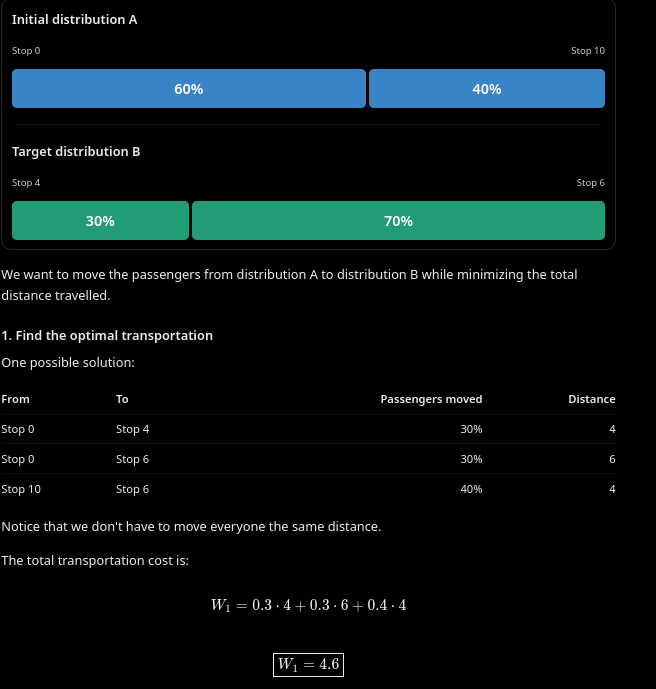

In [54]:
import numpy as np
from scipy.stats import ks_2samp, wasserstein_distance

# Two datasets
data_a = np.array([1, 2, 3, 4, 5])
data_b = np.array([2, 3, 4, 5, 6])

# Kolmogorov-Smirnov test
ks_result = ks_2samp(data_a, data_b)

# Wasserstein distance
wd_result = wasserstein_distance(data_a, data_b)

print(f"KS statistic:       {ks_result.statistic:.4f}")
print(f"KS p-value:         {ks_result.pvalue:.4f}")
print(f"Wasserstein distance: {wd_result:.4f}")

# Another two datasets
data_c = np.array([1,2,3,4])
data_d = np.array([5,6,7,8])

# Kolmogorov-Smirnov test
ks_result = ks_2samp(data_c, data_d)

A = np.array([0] * 99 + [1])

B_near = np.array([0] * 99 + [2])
B_far  = np.array([0] * 99 + [1001])

for B in [B_near, B_far]:
    print("KS:", ks_2samp(A, B).statistic)
    print("Wasserstein:", wasserstein_distance(A, B))

# Wasserstein distance
wd_result = wasserstein_distance(data_c, data_d)

print(f"KS statistic:       {ks_result.statistic:.4f}")
print(f"KS p-value:         {ks_result.pvalue:.4f}")
print(f"Wasserstein distance: {wd_result:.4f}")

# Locations
a = [0, 10]
b = [4, 6]

# Probability masses
weights_a = [0.6, 0.4]
weights_b = [0.3, 0.7]

distance = wasserstein_distance(
    a, b,
    u_weights=weights_a,
    v_weights=weights_b
)

print(f"Wasserstein distane with probability masses: {distance:.4f}")

KS statistic:       0.2000
KS p-value:         1.0000
Wasserstein distance: 1.0000
KS: 0.010000000000000009
Wasserstein: 0.010000000000000009
KS: 0.010000000000000009
Wasserstein: 10.000000000000009
KS statistic:       1.0000
KS p-value:         0.0286
Wasserstein distance: 4.0000
Wasserstein distane with probability masses: 4.6000
